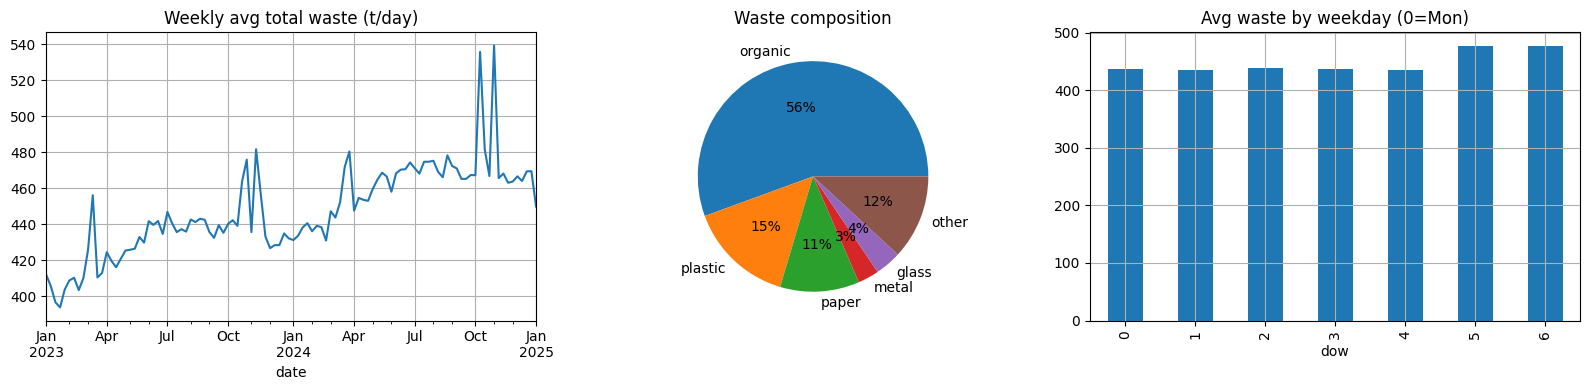

total         1.00
temp          0.21
festival      0.52
is_weekend    0.53
Name: total, dtype: float64
Ridge (baseline)     MAE = 9.87 t/day | MAPE = 2.03%
GradientBoosting     MAE = 15.25 t/day | MAPE = 3.03%
Best model: Ridge (baseline)


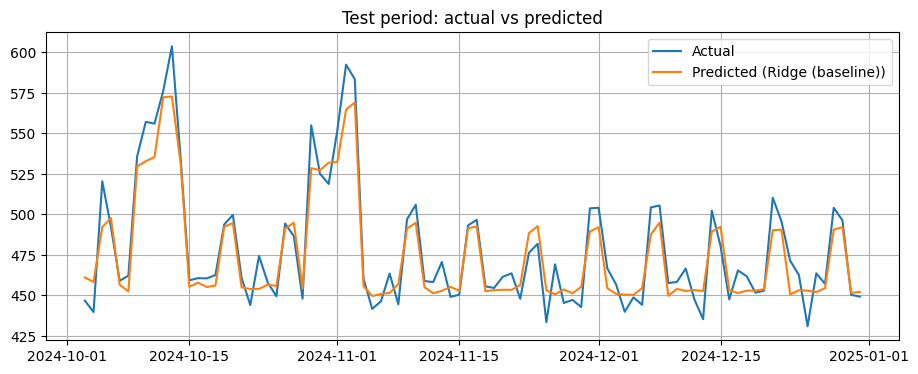

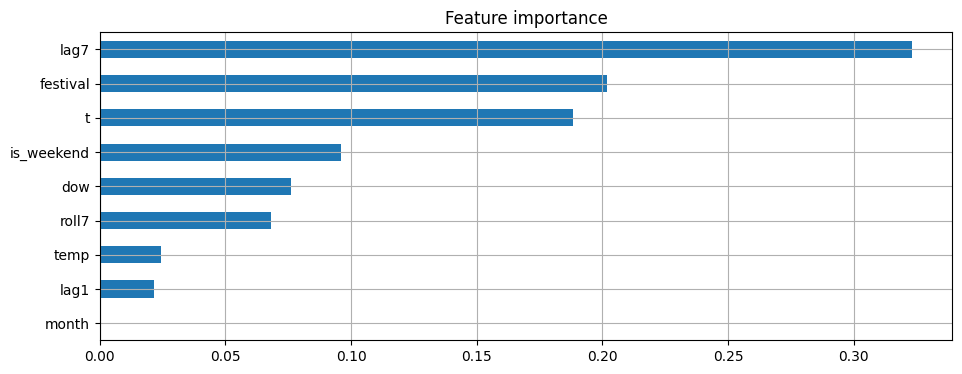

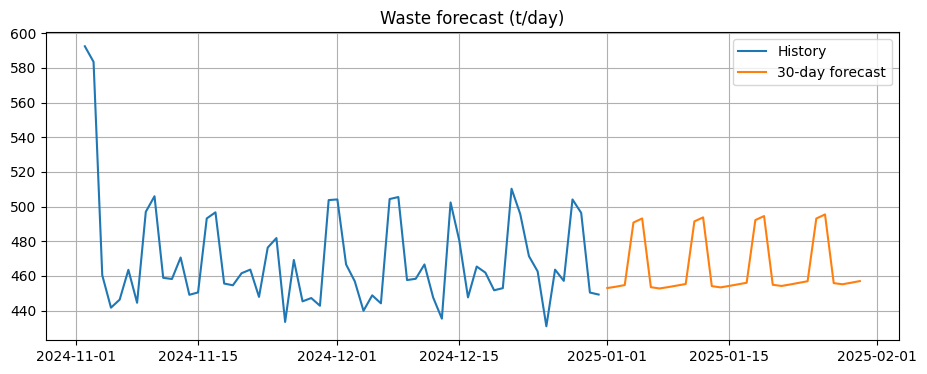

estimated waste for tomarrow(tonnes):
organic    249.5
plastic     67.9
paper       50.7
metal       13.6
glass       16.9
other       54.5
dtype: float64
Optimal allocation found ✅


,Baseline (landfill-heavy),Optimized (LP),Improvement
Energy (MWh/day),86.72,669.34,582.62
CO2 avoided (t/day),27.97,224.55,196.58
Net value (Rs lakh/day),3.73,51.39,47.66
Landfill share (%),86.80,20.53,-66.27


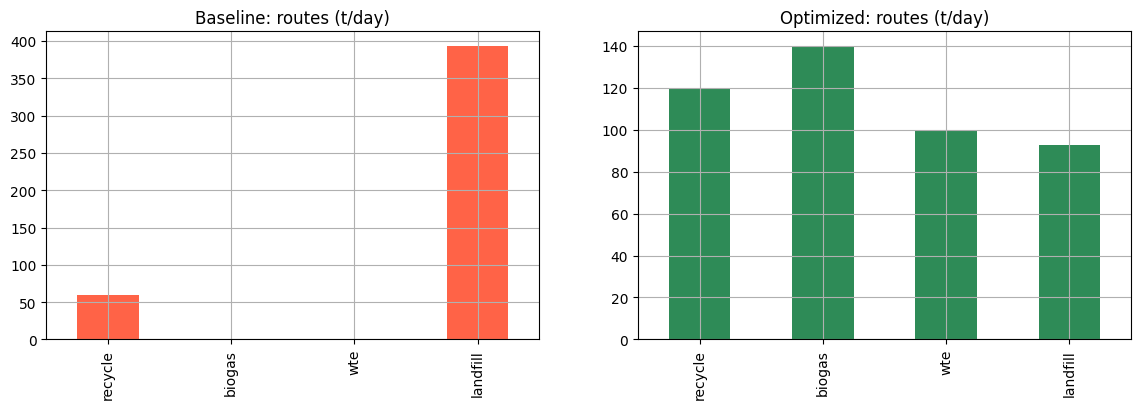

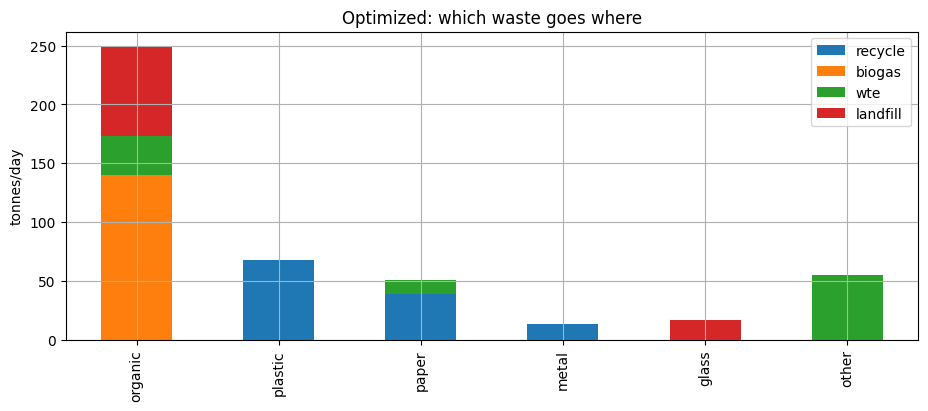

carbon Rs/t,0,1500,3000
tariff Rs/kWh,,,
3.0,28.11,31.41,34.70
4.5,37.99,41.35,44.72
6.0,48.03,51.39,54.76
8.0,61.41,64.78,68.15
10.0,74.80,78.17,81.54


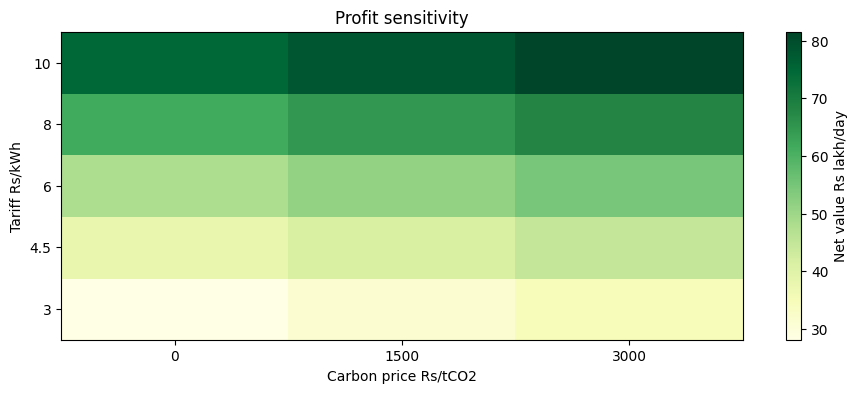

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [2]:
!pip -q install gradio
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linprog
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
np.random.seed(42)
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
WASTE = ['organic', 'plastic', 'paper', 'metal', 'glass', 'other']
dates = pd.date_range('2023-01-01', '2024-12-31', freq='D')
n = len(dates)
df = pd.DataFrame({'date': dates})
df['dow'] = df.date.dt.dayofweek
df['month'] = df.date.dt.month
df['is_weekend'] = (df.dow >= 5).astype(int)
# temperature (Rajasthan-like): hot summers, mild winters
df['temp'] = 26 + 12*np.sin(2*np.pi*(df.date.dt.dayofyear-100)/365) + np.random.normal(0, 1.5, n)
# festival windows (Diwali, Holi etc. - approximate)
fest = ['2023-03-07','2023-11-12','2024-03-25','2024-11-01','2023-10-24','2024-10-12']
df['festival'] = 0
for f in fest:
    df.loc[(df.date >= pd.Timestamp(f) - pd.Timedelta(days=3)) & (df.date <= pd.Timestamp(f) + pd.Timedelta(days=2)), 'festival'] = 1
growth = 1 + 0.08 * np.arange(n) / 365          # 8% yearly population growth
base = {'organic':220, 'plastic':60, 'paper':45, 'metal':12, 'glass':15, 'other':48}  # tonnes/day
for w, b in base.items():
    eff = 1 + (0.12 if w=='organic' else 0.05)*df.is_weekend + 0.18*df.festival
    eff += (0.004*(df.temp-26) if w=='organic' else 0)
    df[w] = b * growth * eff * np.random.normal(1, 0.04, n)
df['total'] = df[WASTE].sum(axis=1)
df.head()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.set_index('date')['total'].resample('W').mean().plot(ax=ax[0], title='Weekly avg total waste (t/day)')
df[WASTE].mean().plot.pie(ax=ax[1], autopct='%1.0f%%', title='Waste composition'); ax[1].set_ylabel('')
df.groupby('dow')['total'].mean().plot.bar(ax=ax[2], title='Avg waste by weekday (0=Mon)')
plt.tight_layout(); plt.show()
print(df[['total','temp','festival','is_weekend']].corr()['total'].round(2))
d = df[['date','total','dow','month','is_weekend','temp','festival']].copy()
d['t'] = np.arange(len(d))
d['lag1'] = d.total.shift(1); d['lag7'] = d.total.shift(7)
d['roll7'] = d.total.shift(1).rolling(7).mean()
d = d.dropna().reset_index(drop=True)
FEATS = ['dow','month','is_weekend','temp','festival','t','lag1','lag7','roll7']
split = len(d) - 90                       # last 90 days = test
Xtr, Xte, ytr, yte = d.loc[:split-1, FEATS], d.loc[split:, FEATS], d.total[:split], d.total[split:]

models = {'Ridge (baseline)': Ridge(alpha=1.0),
          'GradientBoosting': GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)}
res = {}
for name, m in models.items():
    m.fit(Xtr, ytr); p = m.predict(Xte)
    res[name] = (mean_absolute_error(yte, p), mean_absolute_percentage_error(yte, p)*100, p)
    print(f"{name:20s} MAE = {res[name][0]:.2f} t/day | MAPE = {res[name][1]:.2f}%")
best = min(res, key=lambda k: res[k][0]); print('Best model:', best)

plt.plot(d.date[split:], yte.values, label='Actual'); plt.plot(d.date[split:], res[best][2], label=f'Predicted ({best})')
plt.title('Test period: actual vs predicted'); plt.legend(); plt.show()

# Feature importance (agar GB best hai)
gb = models['GradientBoosting']
pd.Series(gb.feature_importances_, index=FEATS).sort_values().plot.barh(title='Feature importance'); plt.show()
model = models[best]
hist = list(d.total.values)
last_date = d.date.iloc[-1]; last_t = d.t.iloc[-1]
rows = []
for i in range(1, 31):
    dt = last_date + pd.Timedelta(days=i)
    temp = 26 + 12*np.sin(2*np.pi*(dt.dayofyear-100)/365)
    x = pd.DataFrame([{'dow':dt.dayofweek,'month':dt.month,'is_weekend':int(dt.dayofweek>=5),'temp':temp,
                       'festival':0,'t':last_t+i,'lag1':hist[-1],'lag7':hist[-7],'roll7':np.mean(hist[-7:])}])[FEATS]
    y = float(model.predict(x)[0]); hist.append(y); rows.append((dt, y))
fc = pd.DataFrame(rows, columns=['date','forecast_total_t'])
plt.plot(d.date[-60:], d.total[-60:], label='History'); plt.plot(fc.date, fc.forecast_total_t, label='30-day forecast')
plt.title('Waste forecast (t/day)'); plt.legend(); plt.show()

# composition = last 90 days ka average share
share = (df[WASTE].tail(90).sum() / df.total.tail(90).sum())
tomorrow = fc.forecast_total_t.iloc[0] * share
print('estimated waste for tomarrow(tonnes):'); print(tomorrow.round(1))
ROUTES = ['recycle', 'biogas', 'wte', 'landfill']   # wte = waste-to-energy incineration
nan = np.nan
# kWh electricity-equivalent per tonne
ENERGY = pd.DataFrame({'recycle':[0,5000,3000,6000,300,nan],
                       'biogas': [200,nan,nan,nan,nan,nan],
                       'wte':    [400,2000,800,nan,nan,1500],
                       'landfill':[0,0,0,0,0,0]}, index=WASTE)
# Rs/tonne revenue from selling recovered material
REVENUE = pd.DataFrame({'recycle':[0,12000,5000,25000,1500,nan],
                        'biogas': [800,nan,nan,nan,nan,nan],     # digestate/compost sale
                        'wte':    [0,0,0,nan,nan,0],
                        'landfill':[0]*6}, index=WASTE)
# kg CO2e avoided vs. dumping (landfill organic = methane problem, so biogas avoids a lot)
CO2 = pd.DataFrame({'recycle':[0,1500,900,2500,300,nan],
                    'biogas': [450,nan,nan,nan,nan,nan],
                    'wte':    [150,-1500,200,nan,nan,-300],      # burning plastic emits CO2 (negative)
                    'landfill':[0]*6}, index=WASTE)
COST = pd.Series({'recycle':1500, 'biogas':1200, 'wte':2500, 'landfill':800})   # Rs/t processing
CAPACITY_DEFAULT = {'recycle':120, 'biogas':140, 'wte':100, 'landfill':1e9}       # t/day plant capacity

def value_matrix(tariff=6.0, carbon_price=1500):
    """Net value in Rs per tonne for each (waste, route)."""
    return ENERGY*tariff + REVENUE + CO2/1000*carbon_price - COST
value_matrix().round(0)
def optimize(waste_t, tariff=6.0, carbon_price=1500, capacity=None, min_recycle_share=0.0):
    cap = capacity or CAPACITY_DEFAULT
    V = value_matrix(tariff, carbon_price)
    allowed = ENERGY.notna()
    idx = [(w, r) for w in WASTE for r in ROUTES if allowed.loc[w, r]]
    c = [-V.loc[w, r] for w, r in idx]                                  # linprog minimizes
    # equality: each waste fully allocated
    A_eq = [[1 if w == ww else 0 for (ww, r) in idx] for w in WASTE]
    b_eq = [waste_t[w] for w in WASTE]
    # inequality: capacity per route
    A_ub, b_ub = [], []
    for r in ROUTES:
        A_ub.append([1 if rr == r else 0 for (w, rr) in idx]); b_ub.append(cap[r])
    # min recycling share:  -sum(recycle) <= -share * total
    A_ub.append([-1 if rr == 'recycle' else 0 for (w, rr) in idx]); b_ub.append(-min_recycle_share * sum(waste_t.values()))
    sol = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method='highs')
    if not sol.success:
        return None, sol.message
    alloc = pd.DataFrame(0.0, index=WASTE, columns=ROUTES)
    for (w, r), v in zip(idx, sol.x): alloc.loc[w, r] = v
    return alloc, None

def impact(alloc, tariff=6.0, carbon_price=1500):
    e = (alloc * ENERGY.fillna(0)).sum().sum()                  # kWh
    co2 = (alloc * CO2.fillna(0)).sum().sum() / 1000            # tCO2e avoided
    money = (alloc * value_matrix(tariff, carbon_price).fillna(0)).sum().sum()
    return {'Energy (MWh/day)': e/1000, 'CO2 avoided (t/day)': co2, 'Net value (Rs lakh/day)': money/1e5,
            'Landfill share (%)': alloc['landfill'].sum()/alloc.values.sum()*100}

alloc, err = optimize(tomorrow.to_dict(), min_recycle_share=0.25)
print(err or 'Optimal allocation found ✅'); alloc.round(1)
# Baseline = aaj ka typical Indian practice: ~80% landfill, thoda recycling
tw = tomorrow.to_dict()
base_alloc = pd.DataFrame(0.0, index=WASTE, columns=ROUTES)
for w in WASTE:
    rec = 0.15 if ENERGY.loc[w,'recycle'] == ENERGY.loc[w,'recycle'] else 0   # recycle only if allowed
    base_alloc.loc[w,'recycle'] = tw[w]*rec; base_alloc.loc[w,'landfill'] = tw[w]*(1-rec)
cmp = pd.DataFrame({'Baseline (landfill-heavy)': impact(base_alloc), 'Optimized (LP)': impact(alloc)}).round(2)
cmp['Improvement'] = (cmp['Optimized (LP)'] - cmp['Baseline (landfill-heavy)']).round(2)
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
base_alloc.sum().plot.bar(ax=ax[0], title='Baseline: routes (t/day)', color='tomato')
alloc.sum().plot.bar(ax=ax[1], title='Optimized: routes (t/day)', color='seagreen'); plt.show()
alloc.plot.bar(stacked=True, title='Optimized: which waste goes where'); plt.ylabel('tonnes/day'); plt.show()
tariffs = [3, 4.5, 6, 8, 10]; carbons = [0, 1500, 3000]
out = pd.DataFrame(index=tariffs, columns=carbons, dtype=float)
for t in tariffs:
    for cp in carbons:
        a, _ = optimize(tw, tariff=t, carbon_price=cp, min_recycle_share=0.25)
        out.loc[t, cp] = impact(a, t, cp)['Net value (Rs lakh/day)']
out.index.name = 'tariff Rs/kWh'; out.columns.name = 'carbon Rs/t'
display(out.round(2))
plt.imshow(out.values.astype(float), aspect='auto', cmap='YlGn', origin='lower')
plt.xticks(range(len(carbons)), carbons); plt.yticks(range(len(tariffs)), tariffs)
plt.colorbar(label='Net value Rs lakh/day'); plt.xlabel('Carbon price Rs/tCO2'); plt.ylabel('Tariff Rs/kWh')
plt.title('Profit sensitivity'); plt.grid(False); plt.show()
import gradio as gr

def run_dashboard(total_waste, organic_pct, min_recycle, tariff, carbon_price, wte_cap):
    comp = share.copy()
    comp['organic'] = organic_pct/100
    others = comp.drop('organic'); comp[others.index] = others / others.sum() * (1 - organic_pct/100)
    wt = (comp * total_waste).to_dict()
    cap = dict(CAPACITY_DEFAULT); cap['wte'] = wte_cap
    a, err = optimize(wt, tariff, carbon_price, cap, min_recycle/100)
    if a is None:
        return None, pd.DataFrame({'Error':[ 'Infeasible: capacity badhao ya recycling % kam karo' ]}), None
    m = impact(a, tariff, carbon_price)
    fig, ax = plt.subplots(figsize=(6, 4)); a.plot.bar(stacked=True, ax=ax); ax.set_ylabel('tonnes/day'); plt.tight_layout()
    summary = pd.DataFrame({'Metric': list(m.keys()), 'Value': [round(v, 2) for v in m.values()]})
    return fig, summary, a.round(1).reset_index().rename(columns={'index':'waste'})

# ---------------- ADVANCED CONNECTED DASHBOARD ----------------
# Existing forecasting, graphs, optimization and impact calculations above are preserved.
# The following section adds a persistent records table and connects it to this project's
# existing waste categories and ENERGY model.
import sqlite3, os
from datetime import datetime

DB_PATH = 'smart_waste_records.db'
ENERGY_FACTORS = {
    # estimated kWh per tonne: use the best available route value already defined above
    w: float(pd.to_numeric(ENERGY.loc[w], errors='coerce').max(skipna=True) or 0)
    for w in WASTE
}

def db_connect():
    return sqlite3.connect(DB_PATH)

def init_database():
    with db_connect() as con:
        con.execute('''CREATE TABLE IF NOT EXISTS waste_records (
            record_id INTEGER PRIMARY KEY AUTOINCREMENT,
            location TEXT NOT NULL,
            waste_date TEXT NOT NULL,
            category TEXT NOT NULL,
            weight_kg REAL NOT NULL,
            estimated_energy_kwh REAL NOT NULL,
            created_at TEXT NOT NULL
        )''')
        con.execute('''CREATE TABLE IF NOT EXISTS optimization_history (
            run_id INTEGER PRIMARY KEY AUTOINCREMENT,
            run_time TEXT NOT NULL,
            total_waste_t REAL NOT NULL,
            tariff REAL NOT NULL,
            carbon_price REAL NOT NULL,
            min_recycle_pct REAL NOT NULL,
            energy_mwh REAL NOT NULL,
            co2_avoided_t REAL NOT NULL,
            net_value_lakh REAL NOT NULL,
            landfill_share_pct REAL NOT NULL
        )''')
        # Add a small sample based on the project's existing synthetic dataset only once.
        count = con.execute('SELECT COUNT(*) FROM waste_records').fetchone()[0]
        if count == 0:
            seed_rows = []
            for _, row in df.tail(30).iterrows():
                for category in WASTE:
                    kg = max(0.0, float(row[category]) * 1000.0)
                    seed_rows.append((
                        'Sample Zone', pd.to_datetime(row['date']).strftime('%Y-%m-%d'),
                        category, round(kg, 2), round(kg / 1000.0 * ENERGY_FACTORS[category], 2),
                        datetime.now().isoformat(timespec='seconds')
                    ))
            con.executemany('''INSERT INTO waste_records
                (location,waste_date,category,weight_kg,estimated_energy_kwh,created_at)
                VALUES (?,?,?,?,?,?)''', seed_rows)

init_database()

RECORD_COLUMNS = ['Record ID', 'Location', 'Waste Date', 'Category', 'Weight (kg)', 'Estimated Energy (kWh)']

def fetch_records(search_text='', category_filter='All categories', date_from='', date_to=''):
    query = '''SELECT record_id, location, waste_date, category, weight_kg, estimated_energy_kwh
               FROM waste_records WHERE 1=1'''
    params = []
    if search_text and search_text.strip():
        term = '%' + search_text.strip() + '%'
        query += ' AND (CAST(record_id AS TEXT) LIKE ? OR location LIKE ? OR category LIKE ? OR waste_date LIKE ?)'
        params.extend([term, term, term, term])
    if category_filter and category_filter != 'All categories':
        query += ' AND category = ?'; params.append(category_filter)
    if date_from:
        query += ' AND waste_date >= ?'; params.append(date_from)
    if date_to:
        query += ' AND waste_date <= ?'; params.append(date_to)
    query += ' ORDER BY waste_date DESC, record_id DESC'
    with db_connect() as con:
        data = con.execute(query, params).fetchall()
    return pd.DataFrame(data, columns=RECORD_COLUMNS)

def table_summary(records_df=None):
    if records_df is None:
        records_df = fetch_records()
    if records_df.empty:
        return pd.DataFrame({'Metric':['Total records','Total waste (kg)','Estimated energy (kWh)'], 'Value':[0,0,0]})
    return pd.DataFrame({
        'Metric':['Total records','Total waste (kg)','Estimated energy (kWh)','Categories represented','Locations represented'],
        'Value':[len(records_df), round(records_df['Weight (kg)'].sum(),2),
                 round(records_df['Estimated Energy (kWh)'].sum(),2),
                 records_df['Category'].nunique(), records_df['Location'].nunique()]
    })

def refresh_records(search_text='', category_filter='All categories', date_from='', date_to=''):
    records = fetch_records(search_text, category_filter, date_from, date_to)
    return records, table_summary(records)

def add_record(location, waste_date, category, weight_kg):
    try:
        location = str(location).strip()
        category = str(category).strip().lower()
        weight_kg = float(weight_kg)
        date_value = pd.to_datetime(waste_date, errors='raise').strftime('%Y-%m-%d')
        if not location: return fetch_records(), '❌ Location is required.'
        if category not in WASTE: return fetch_records(), '❌ Please choose a valid waste category.'
        if weight_kg <= 0: return fetch_records(), '❌ Weight must be greater than zero.'
        energy_kwh = weight_kg / 1000.0 * ENERGY_FACTORS[category]
        with db_connect() as con:
            con.execute('''INSERT INTO waste_records
                (location,waste_date,category,weight_kg,estimated_energy_kwh,created_at)
                VALUES (?,?,?,?,?,?)''', (location, date_value, category, weight_kg,
                round(energy_kwh,2), datetime.now().isoformat(timespec='seconds')))
        return fetch_records(), f'✅ Record added. Estimated energy: {energy_kwh:,.2f} kWh.'
    except Exception as e:
        return fetch_records(), f'❌ Could not add record: {e}'

def update_record(record_id, location, waste_date, category, weight_kg):
    try:
        rid = int(record_id); location = str(location).strip(); category = str(category).strip().lower()
        date_value = pd.to_datetime(waste_date, errors='raise').strftime('%Y-%m-%d')
        weight_kg = float(weight_kg)
        if not location or category not in WASTE or weight_kg <= 0:
            return fetch_records(), '❌ Check location, category and positive weight.'
        energy_kwh = weight_kg / 1000.0 * ENERGY_FACTORS[category]
        with db_connect() as con:
            cur = con.execute('''UPDATE waste_records SET location=?, waste_date=?, category=?,
                weight_kg=?, estimated_energy_kwh=? WHERE record_id=?''',
                (location,date_value,category,weight_kg,round(energy_kwh,2),rid))
        if cur.rowcount == 0: return fetch_records(), '❌ Record ID not found.'
        return fetch_records(), f'✅ Record {rid} updated.'
    except Exception as e:
        return fetch_records(), f'❌ Could not update record: {e}'

def delete_record(record_id):
    try:
        rid = int(record_id)
        with db_connect() as con:
            cur = con.execute('DELETE FROM waste_records WHERE record_id=?', (rid,))
        if cur.rowcount == 0: return fetch_records(), '❌ Record ID not found.'
        return fetch_records(), f'🗑️ Record {rid} deleted.'
    except Exception as e:
        return fetch_records(), f'❌ Enter a valid Record ID. {e}'

def export_records(search_text='', category_filter='All categories', date_from='', date_to=''):
    records = fetch_records(search_text, category_filter, date_from, date_to)
    path = 'waste_records_export.csv'
    records.to_csv(path, index=False)
    return path

def load_history():
    with db_connect() as con:
        rows = con.execute('''SELECT run_id, run_time, total_waste_t, tariff, carbon_price,
            min_recycle_pct, energy_mwh, co2_avoided_t, net_value_lakh, landfill_share_pct
            FROM optimization_history ORDER BY run_id DESC''').fetchall()
    return pd.DataFrame(rows, columns=['Run ID','Run time','Total waste (t/day)','Tariff (Rs/kWh)',
        'Carbon price (Rs/tCO2)','Min recycling (%)','Energy (MWh/day)','CO2 avoided (t/day)',
        'Net value (Rs lakh/day)','Landfill share (%)'])

def run_dashboard(total_waste, organic_pct, min_recycle, tariff, carbon_price, wte_cap):
    comp = share.copy()
    comp['organic'] = organic_pct/100
    others = comp.drop('organic'); comp[others.index] = others / others.sum() * (1 - organic_pct/100)
    wt = (comp * total_waste).to_dict()
    cap = dict(CAPACITY_DEFAULT); cap['wte'] = wte_cap
    a, err = optimize(wt, tariff, carbon_price, cap, min_recycle/100)
    if a is None:
        return None, pd.DataFrame({'Error':['Infeasible: capacity badhao ya recycling % kam karo']}), None, pd.DataFrame({'Status':[err or 'No feasible solution']})
    m = impact(a, tariff, carbon_price)
    fig, ax = plt.subplots(figsize=(7, 4)); a.plot.bar(stacked=True, ax=ax); ax.set_ylabel('tonnes/day'); ax.set_title('Optimized waste allocation'); plt.tight_layout()
    summary = pd.DataFrame({'Metric':list(m.keys()), 'Value':[round(v,2) for v in m.values()]})
    allocation = a.round(2).reset_index().rename(columns={'index':'Waste category'})
    # Save each successful optimization so users can compare runs later.
    with db_connect() as con:
        con.execute('''INSERT INTO optimization_history
            (run_time,total_waste_t,tariff,carbon_price,min_recycle_pct,energy_mwh,co2_avoided_t,net_value_lakh,landfill_share_pct)
            VALUES (?,?,?,?,?,?,?,?,?)''', (datetime.now().isoformat(timespec='seconds'), float(total_waste),
            float(tariff),float(carbon_price),float(min_recycle),float(m['Energy (MWh/day)']),
            float(m['CO2 avoided (t/day)']),float(m['Net value (Rs lakh/day)']),float(m['Landfill share (%)'])))
    capacity_df = pd.DataFrame({'Route':list(cap.keys()), 'Capacity (t/day)':list(cap.values()),
        'Allocated (t/day)':[float(a[r].sum()) for r in cap.keys()]})
    capacity_df['Utilization (%)'] = np.where(capacity_df['Capacity (t/day)'] < 1e8,
        (capacity_df['Allocated (t/day)'] / capacity_df['Capacity (t/day)'] * 100).round(1), 0)
    capacity_df['Alert'] = np.where(capacity_df['Utilization (%)'] >= 90, '⚠️ Near capacity', 'OK')
    return fig, summary, allocation, capacity_df

def refresh_history():
    return load_history()

def records_chart():
    records = fetch_records()
    if records.empty:
        fig, ax = plt.subplots(figsize=(6,3)); ax.set_title('No records available'); return fig
    grouped = records.groupby('Category')['Weight (kg)'].sum().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(7,4)); grouped.plot(kind='bar', ax=ax)
    ax.set_title('Saved waste by category'); ax.set_ylabel('Weight (kg)'); plt.tight_layout()
    return fig

# Integrated Gradio app: existing optimizer + connected table/CRUD + reports/history.
with gr.Blocks(title='Smart Waste-to-Energy Optimizer') as demo:
    gr.Markdown('# ♻️ Smart Waste-to-Energy Management System')
    gr.Markdown('Existing forecasting and optimization remain intact. Added features use a local SQLite database so saved records remain available after restarting the app in the same folder.')
    with gr.Tab('⚙️ Optimizer Dashboard'):
        with gr.Row():
            total_waste = gr.Slider(200, 800, value=float(tomorrow.sum()), label='Total waste (t/day)')
            organic_pct = gr.Slider(30, 70, value=55, label='Organic waste (%)')
        with gr.Row():
            min_recycle = gr.Slider(0, 60, value=25, label='Minimum recycling (%)')
            tariff = gr.Slider(2, 12, value=6, step=0.5, label='Electricity tariff (Rs/kWh)')
        with gr.Row():
            carbon_price = gr.Slider(0, 4000, value=1500, step=100, label='Carbon price (Rs/tCO2)')
            wte_cap = gr.Slider(20, 250, value=100, label='WtE plant capacity (t/day)')
        optimize_btn = gr.Button('Run optimization', variant='primary')
        allocation_plot = gr.Plot(label='Optimized allocation')
        impact_table = gr.Dataframe(label='Impact summary', interactive=False)
        with gr.Row():
            allocation_table = gr.Dataframe(label='Waste allocation table', interactive=False)
            capacity_table = gr.Dataframe(label='Plant capacity & alerts', interactive=False)
        optimize_btn.click(run_dashboard, [total_waste, organic_pct, min_recycle, tariff, carbon_price, wte_cap],
                           [allocation_plot, impact_table, allocation_table, capacity_table])
    with gr.Tab('🗂️ Waste Records Table'):
        gr.Markdown('### Add, edit, delete, search and export waste records')
        with gr.Row():
            search_text = gr.Textbox(label='Search ID / location / category / date', placeholder='e.g. Sample Zone or organic')
            category_filter = gr.Dropdown(['All categories'] + WASTE, value='All categories', label='Filter category')
        with gr.Row():
            date_from = gr.Textbox(label='From date (YYYY-MM-DD)', placeholder='Optional')
            date_to = gr.Textbox(label='To date (YYYY-MM-DD)', placeholder='Optional')
            filter_btn = gr.Button('Apply filters')
            reset_btn = gr.Button('Show all records')
        records_table = gr.Dataframe(value=fetch_records(), headers=RECORD_COLUMNS, interactive=False, label='Saved waste records')
        records_summary = gr.Dataframe(value=table_summary(), interactive=False, label='Filtered table summary')
        with gr.Row():
            with gr.Column():
                gr.Markdown('#### ➕ Add a record')
                add_location = gr.Textbox(label='Location', value='Sample Zone')
                add_date = gr.Textbox(label='Waste date (YYYY-MM-DD)', value=datetime.now().strftime('%Y-%m-%d'))
                add_category = gr.Dropdown(WASTE, value='organic', label='Waste category')
                add_weight = gr.Number(value=100, minimum=0.01, label='Weight (kg)')
                add_btn = gr.Button('Add record', variant='primary')
            with gr.Column():
                gr.Markdown('#### ✏️ Edit a record')
                edit_id = gr.Number(value=1, precision=0, label='Record ID to update')
                edit_location = gr.Textbox(label='New location')
                edit_date = gr.Textbox(label='New waste date (YYYY-MM-DD)')
                edit_category = gr.Dropdown(WASTE, value='organic', label='New category')
                edit_weight = gr.Number(value=100, minimum=0.01, label='New weight (kg)')
                edit_btn = gr.Button('Update record')
        with gr.Row():
            delete_id = gr.Number(value=1, precision=0, label='Record ID to delete')
            delete_btn = gr.Button('Delete record', variant='stop')
            export_btn = gr.Button('Export filtered table to CSV')
            export_file = gr.File(label='CSV export')
        record_status = gr.Markdown()
        filter_btn.click(refresh_records, [search_text, category_filter, date_from, date_to], [records_table, records_summary])
        reset_btn.click(lambda: (fetch_records(), table_summary(), '', 'All categories', '', ''),
                        outputs=[records_table, records_summary, search_text, category_filter, date_from, date_to])
        add_btn.click(add_record, [add_location, add_date, add_category, add_weight], [records_table, record_status]).then(
            lambda: table_summary(), outputs=records_summary)
        edit_btn.click(update_record, [edit_id, edit_location, edit_date, edit_category, edit_weight], [records_table, record_status]).then(
            lambda: table_summary(), outputs=records_summary)
        delete_btn.click(delete_record, [delete_id], [records_table, record_status]).then(
            lambda: table_summary(), outputs=records_summary)
        export_btn.click(export_records, [search_text, category_filter, date_from, date_to], export_file)
    with gr.Tab('📈 Analytics & Reports'):
        gr.Markdown('### Analytics from saved records and previous optimization runs')
        records_plot = gr.Plot(value=records_chart(), label='Waste by category')
        refresh_chart_btn = gr.Button('Refresh category chart')
        history_table = gr.Dataframe(value=load_history(), interactive=False, label='Optimization history')
        refresh_history_btn = gr.Button('Refresh optimization history')
        refresh_chart_btn.click(records_chart, outputs=records_plot)
        refresh_history_btn.click(refresh_history, outputs=history_table)

demo.launch(share=False, debug=False)
